# Filtering, excluding ontario individuals
start from populations.snps.vcf

In [1]:
vcftools --vcf populations.snps.vcf --out exontario --remove blacklist --recode --recode-INFO-all


VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf populations.snps.vcf
	--remove blacklist
	--recode-INFO-all
	--out exontario
	--recode

Excluding individuals in 'exclude' list
After filtering, kept 113 out of 118 Individuals
Outputting VCF file...
After filtering, kept 126978 out of a possible 126978 Sites
Run Time = 19.00 seconds


In [ ]:
# Calculate missingness and depth stats

In [2]:
mkdir all_data_stats
vcftools --vcf exontario.recode.vcf --out all_data_stats/all.snps --missing-indv
vcftools --vcf exontario.recode.vcf --out all_data_stats/all.snps --depth
vcftools --vcf exontario.recode.vcf --out all_data_stats/all.snps --site-mean-depth
vcftools --vcf exontario.recode.vcf --out all_data_stats/all.snps --missing-site

mkdir: cannot create directory ‘all_data_stats’: File exists

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf exontario.recode.vcf
	--missing-indv
	--out all_data_stats/all.snps

After filtering, kept 113 out of 113 Individuals
Outputting Individual Missingness
After filtering, kept 126978 out of a possible 126978 Sites
Run Time = 2.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf exontario.recode.vcf
	--depth
	--out all_data_stats/all.snps

After filtering, kept 113 out of 113 Individuals
Outputting Mean Depth by Individual
After filtering, kept 126978 out of a possible 126978 Sites
Run Time = 1.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf exontario.recode.vcf
	--out all_data_stats/all.snps
	--site-mean-depth

After filtering, kept 113 out of 113 Individuals
Outputting Depth for Each Site
After filtering, kept 126978 out

In [1]:
library(ggplot2)
library(patchwork)
library(dplyr)

plot.vcf.stats <- function(prfx){
  adat  <- read.delim(paste(prfx, ".imiss", sep=""), sep = "\t", header=TRUE)
  a <- ggplot(adat, aes(F_MISS)) + 
      geom_histogram(fill="orange", col="black", alpha=0.6,
                   binwidth=0.05, show.legend=FALSE) + 
      xlim(0.0, 1.0) + ggtitle("FREQ SITES MISSING PER INDIVIDUAL")
  
  bdat  <- read.delim(paste(prfx, ".idepth", sep=""), sep = "\t", header=TRUE)
  b <- ggplot(bdat, aes(MEAN_DEPTH)) + 
      geom_histogram(fill="dodgerblue", col="black", alpha=0.6,
                   binwidth=1, show.legend=FALSE) + 
      xlim(0,200) + ggtitle("MEAN DEPTH PER INDV ACROSS LOCI")
  
  cdat  <- read.delim(paste(prfx, ".lmiss", sep=""), sep = "\t", header=TRUE)
  c <- ggplot(cdat, aes(F_MISS)) + 
      geom_histogram(fill="orange", col="black", alpha=0.6,
                   binwidth=0.05, show.legend=FALSE) + 
      xlim(0.0, 1.0) + ggtitle("FREQ SITES MISSING PER LOCUS")
  
  ddat  <- read.delim(paste(prfx, ".ldepth.mean", sep=""), sep = "\t", header=TRUE)
  d <- ggplot(ddat, aes(MEAN_DEPTH)) + 
      geom_histogram(fill="dodgerblue", col="black", alpha=0.6,
                   binwidth=1, show.legend=FALSE) + 
      xlim(0,200) + ggtitle("MEAN DEPTH PER LOCUS ACROSS INDIVIDUAL")
  
  #options(repr.plot.width=18, repr.plot.height=12)
  print ((a | b) / 
      (c | d))
}


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 61 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


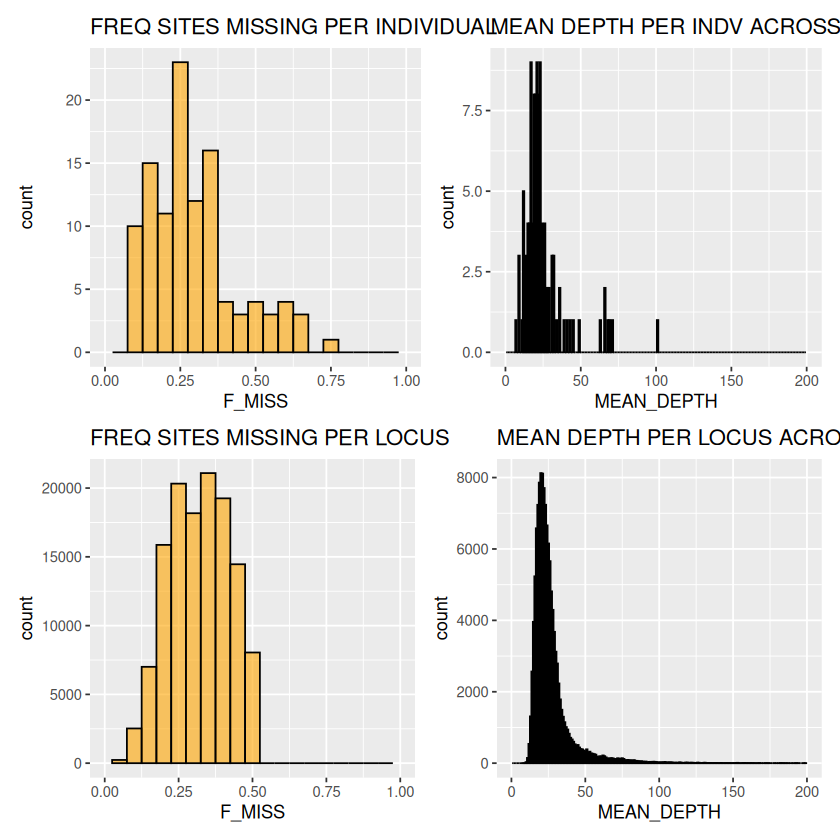

In [3]:
prefix <- "all_data_stats/all.snps"
plot.vcf.stats(prefix)

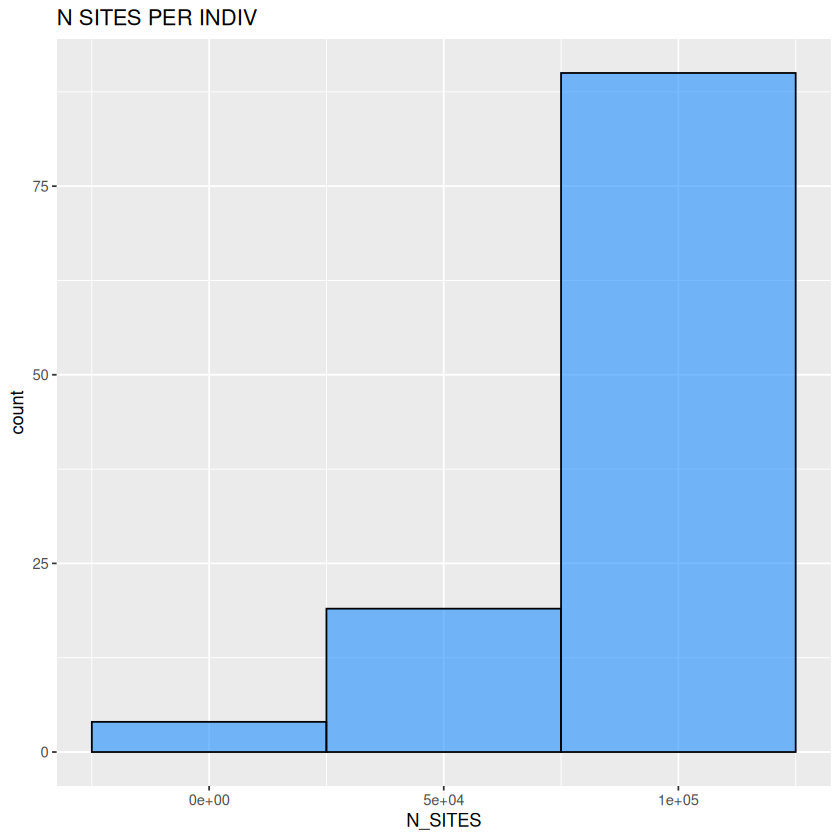

In [4]:
bdat  <- read.delim(paste(prefix, ".idepth", sep=""), sep = "\t", header=TRUE)
  b <- ggplot(bdat, aes(N_SITES)) + 
      geom_histogram(fill="dodgerblue", col="black", alpha=0.6,
                   binwidth=50000, show.legend=FALSE) + 
      ggtitle("N SITES PER INDIV")
  b

In [20]:
#make list of samples with high missingness and high depth to cut
mawk '$3 > 50' ./all_data_stats/all.snps.idepth | cut -f1 > ./all_data_stats/depthover50.indv
mawk '$5 >.50' ./all_data_stats/all.snps.imiss | cut -f1 > ./all_data_stats/missingover50.indv

cat ./all_data_stats/depthover50.indv
cat ./all_data_stats/missingover50.indv

cat ./all_data_stats/depthover50.indv ./all_data_stats/missingover50.indv > ./all_data_stats/blacklist.indv
vcftools --vcf ./exontario.recode.vcf --out ./firstpass --remove ./all_data_stats/blacklist.indv --recode --recode-INFO-all


INDV
sal_CB-06
sal_MC-02
sal_NL-RBS-004
sal_NL-RBS-082
sal_NL-RBS-158
sal_RI-01
sal_WW-05
INDV
sal_AL-01
sal_NL-RBS-029
sal_NL-RBS-169
sal_NL-RBS-171
sal_PE-04
sal_PE-05
sal_RE-04
sal_SJ-04
sal_SJ-06
sal_SJ-07
sal_SS-06
sal_SS-09
sal_SU-02
sal_SU-04
sal_YO-04
sal_YO-05

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf ./exontario.recode.vcf
	--remove ./all_data_stats/blacklist.indv
	--recode-INFO-all
	--out ./firstpass
	--recode

Excluding individuals in 'exclude' list
After filtering, kept 90 out of 113 Individuals
Outputting VCF file...
After filtering, kept 126978 out of a possible 126978 Sites
Run Time = 16.00 seconds


In [21]:
#visualise again
mkdir firstpass_data_stats
vcftools --vcf firstpass.recode.vcf --out firstpass_data_stats/firstpass.snps --missing-indv
vcftools --vcf firstpass.recode.vcf --out firstpass_data_stats/firstpass.snps --depth
vcftools --vcf firstpass.recode.vcf --out firstpass_data_stats/firstpass.snps --site-mean-depth
vcftools --vcf firstpass.recode.vcf --out firstpass_data_stats/firstpass.snps --missing-site

mkdir: cannot create directory ‘firstpass_data_stats’: File exists

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf firstpass.recode.vcf
	--missing-indv
	--out firstpass_data_stats/firstpass.snps

After filtering, kept 90 out of 90 Individuals
Outputting Individual Missingness
After filtering, kept 126978 out of a possible 126978 Sites
Run Time = 1.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf firstpass.recode.vcf
	--depth
	--out firstpass_data_stats/firstpass.snps

After filtering, kept 90 out of 90 Individuals
Outputting Mean Depth by Individual
After filtering, kept 126978 out of a possible 126978 Sites
Run Time = 2.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf firstpass.recode.vcf
	--out firstpass_data_stats/firstpass.snps
	--site-mean-depth

After filtering, kept 90 out of 90 Individuals
Outputting Depth for Each S

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 40 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


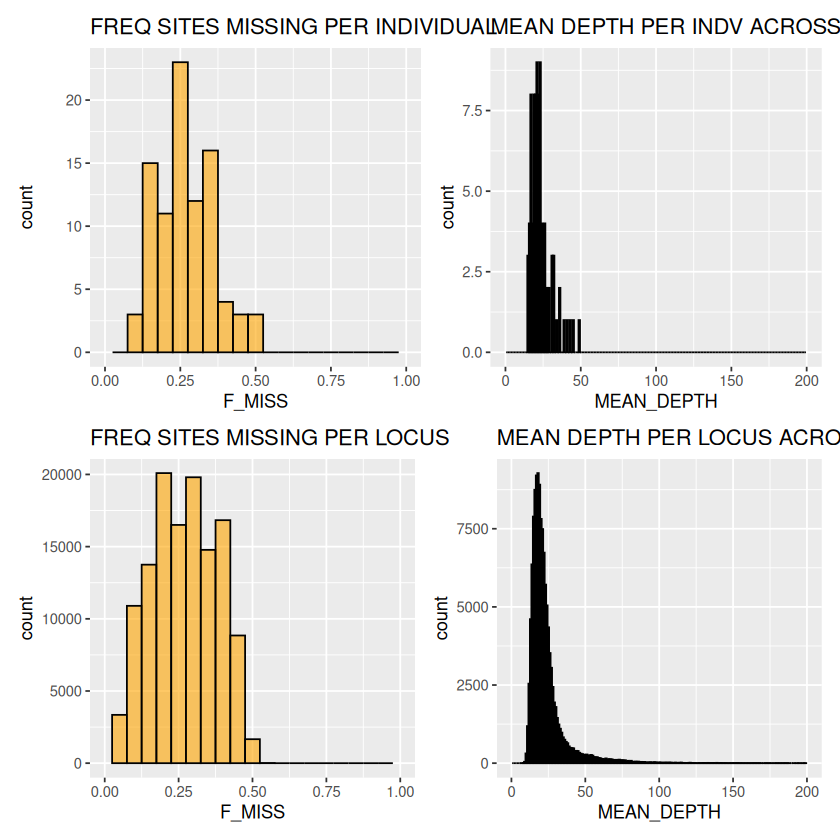

In [2]:
# Note to switch to R and run function again
pathname1 <- "firstpass_data_stats/firstpass.snps"
plot.vcf.stats(pathname1)

In [1]:
#time to start cutting sites. keeping min dp 4, max dp 50, MAC = 3, max missing = 20% (same as laval's protocol)
mkdir mindp4_mac3_mm80
vcftools --vcf firstpass.recode.vcf \
--max-missing 0.80 \
--min-meanDP 4 \
--max-meanDP 50 \
--mac 3 \
--recode --recode-INFO-all \
--out mindp4.mac3.mm80

mkdir: cannot create directory ‘mindp4_mac3_mm80’: File exists

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf firstpass.recode.vcf
	--recode-INFO-all
	--mac 3
	--max-meanDP 50
	--min-meanDP 4
	--max-missing 0.8
	--out mindp4.mac3.mm80
	--recode

After filtering, kept 90 out of 90 Individuals
Outputting VCF file...
After filtering, kept 27468 out of a possible 126978 Sites
Run Time = 6.00 seconds


In [2]:

vcftools --vcf mindp4.mac3.mm80.recode.vcf --out mindp4_mac3_mm80/mindp4.mac3.mm80.snps --missing-indv
vcftools --vcf mindp4.mac3.mm80.recode.vcf --out mindp4_mac3_mm80/mindp4.mac3.mm80.snps --depth
vcftools --vcf mindp4.mac3.mm80.recode.vcf --out mindp4_mac3_mm80/mindp4.mac3.mm80.snps --site-mean-depth
vcftools --vcf mindp4.mac3.mm80.recode.vcf --out mindp4_mac3_mm80/mindp4.mac3.mm80.snps --missing-site


VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf mindp4.mac3.mm80.recode.vcf
	--missing-indv
	--out mindp4_mac3_mm80/mindp4.mac3.mm80.snps

After filtering, kept 90 out of 90 Individuals
Outputting Individual Missingness
After filtering, kept 27468 out of a possible 27468 Sites
Run Time = 1.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf mindp4.mac3.mm80.recode.vcf
	--depth
	--out mindp4_mac3_mm80/mindp4.mac3.mm80.snps

After filtering, kept 90 out of 90 Individuals
Outputting Mean Depth by Individual
After filtering, kept 27468 out of a possible 27468 Sites
Run Time = 0.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf mindp4.mac3.mm80.recode.vcf
	--out mindp4_mac3_mm80/mindp4.mac3.mm80.snps
	--site-mean-depth

After filtering, kept 90 out of 90 Individuals
Outputting Depth for Each Site
After filtering, kept 27468 out of a 

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


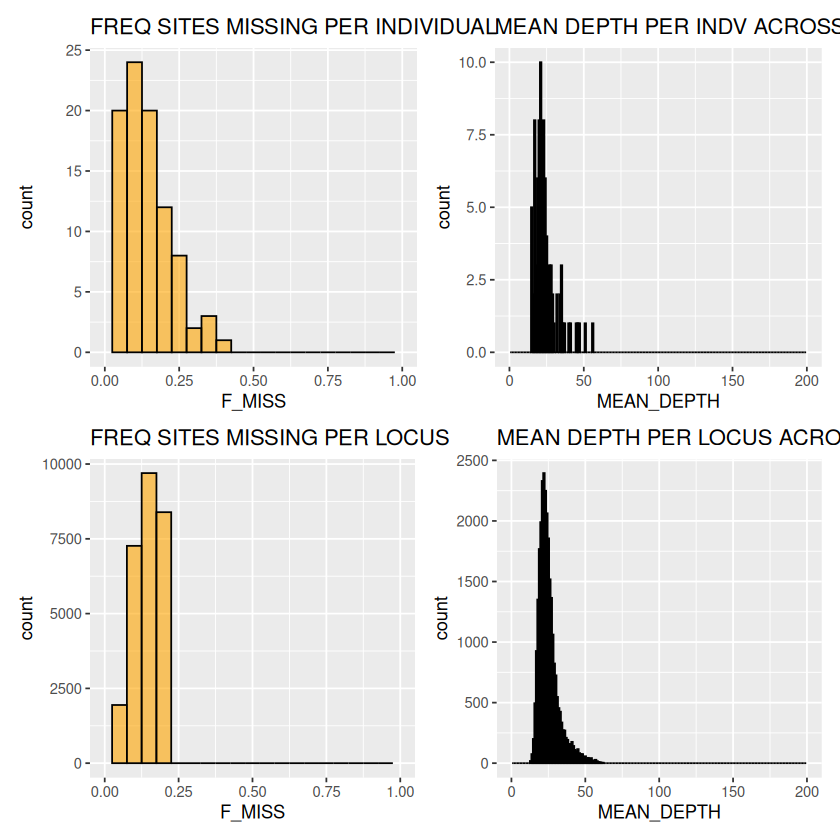

In [2]:
pathname1 <-"mindp4_mac3_mm80/mindp4.mac3.mm80.snps"
plot.vcf.stats(pathname1)

In [4]:
#actually looks pretty good. all indvs have at less than 35% missing. 
#filter high He sites. need to use populations for this, grouped by province for now
stacks populations -V mindp4.mac3.mm80.recode.vcf -M dp4.mac3.mm80.popmap.txt --max-obs-het 0.9 -O maxhet90 --vcf

Logging to 'maxhet90/mindp4.mac3.mm80.recode.p.log'.
Locus/sample distributions will be written to 'maxhet90/mindp4.mac3.mm80.recode.p.log.distribs'.
populations parameters selected:
  Input mode: VCF
  Percent samples limit per population: 0
  Locus Population limit: 1
  Percent samples overall: 0
  Minor allele frequency cutoff: 0
  Maximum observed heterozygosity cutoff: 0.9
  Applying Fst correction: none.
  Pi/Fis kernel smoothing: off
  F-stats kernel smoothing: off
  Bootstrap resampling: off

Parsing population map...
The population map contained 110 samples, 6 population(s), 1 group(s).
Opening the VCF file...
Working on 5 population(s):
    NB: sal_AL-02, sal_MA-01, sal_MC-01, sal_MC-05, sal_MT-02, sal_MT-03, sal_MT-04, sal_MT-06, sal_MT-07, sal_NU-01, sal_NU-03, 
        sal_NU-04, sal_NU-06, sal_NU-08, sal_RE-01, sal_RE-03, sal_RE-05, sal_RI-02, sal_RI-03, sal_RI-04, sal_RI-05, sal_SA-02, 
        sal_SA-03, sal_SJ-01, sal_SJ-03, sal_SJ-05, sal_SJ-09, sal_SJ-11, sal_SU-01, 

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



333116 
333130 
333141 
333183 
333210 
333263 
333324 
333348 
333382 
333453 
333489 
333499 
333524 
333558 
333611 
333641 
333673 
333706 
333798 
333875 
333916 
334040 
334138 
334182 
334195 
334201 
334266 
334271 
334322 
334377 
334398 
334487 
334505 
334542 
334563 
334673 
334695 
334704 
334718 
334785 
334789 
334814 
334851 
334970 
335001 
335057 
335111 
335146 
335307 
335358 
335399 
335561 
335581 
335657 
335732 
335797 
335882 
335898 
335915 
335988 
336045 
336071 
336109 
336116 
336164 
336182 
336233 
336300 
336376 
336502 
336544 
336586 
336604 
336627 
336652 
336706 
336744 
336792 
336851 
336889 
336973 
337130 
337163 
337202 
337275 
337301 
337376 
337436 
337447 
337560 
337564 
337583 
337669 
337723 
337754 
337806 
337916 
337929 
337962 
337996 
338024 
338085 
338213 
338278 
338407 
338452 
338486 
338498 
338572 
338717 
338829 
338862 
339005 
339079 
339142 
339183 
339245 
339376 
339392 
339432 
339475 
339528 
339628 
339706 
339714 


IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



677993 
678137 
678189 
678251 
678321 
678429 
678509 
678512 
678543 
678575 
678586 
678661 
678738 
678763 
678773 
678860 
678941 
678977 
679013 
679159 
679173 
679246 
679292 
679299 
679356 
679404 
679509 
679706 
679733 
679815 
679817 
679822 
680074 
680093 
680184 
680273 
680315 
680358 
680462 
680637 
680658 
680698 
680751 
680807 
681003 
681063 
681095 
681153 
681176 
681209 
681214 
681270 
681365 
681412 
681457 
681499 
681624 
681677 
681710 
681798 
681806 
681819 
681977 
682029 
682106 
682179 
682301 
682352 
682391 
682406 
682424 
682454 
682514 
682620 
682637 
682783 
682849 
682876 
682902 
682954 
682968 
682992 
683027 
683079 
683242 
683277 
683371 
683404 
683425 
683470 
683482 
683521 
683532 
683560 
683591 
683639 
683652 
683738 
683806 
683910 
683956 
684064 
684089 
684156 
684242 
684316 
684331 
684542 
684589 
684644 
684757 
684824 
684836 
684884 
684906 
684920 
685067 
685119 
685133 
685303 
685403 
685418 
685543 
685557 
685591 


In [7]:
#well that actually didn't do much. Good?
#linkage filtering (might be overfiltering at this point, physical linkage shouldn't matter)
vcftools --vcf maxhet90/mindp4.mac3.mm80.recode.p.snps.vcf --out link500 --thin 500 --recode --recode-INFO-all


VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf maxhet90/mindp4.mac3.mm80.recode.p.snps.vcf
	--recode-INFO-all
	--thin 500
	--out link500
	--recode

After filtering, kept 90 out of 90 Individuals
Outputting VCF file...
After filtering, kept 17199 out of a possible 27452 Sites
Run Time = 2.00 seconds


In [8]:
# going back to maxhet90 filtering and checking for invariant sites again
vcftools --vcf maxhet90/mindp4.mac3.mm80.recode.p.snps.vcf \
--out final \
--mac 1 \
--recode --recode-INFO-all


VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--vcf maxhet90/mindp4.mac3.mm80.recode.p.snps.vcf
	--recode-INFO-all
	--mac 1
	--out final
	--recode

After filtering, kept 90 out of 90 Individuals
Outputting VCF file...
After filtering, kept 27452 out of a possible 27452 Sites
Run Time = 4.00 seconds


In [9]:
vcf2phylip.py -i ./final.recode.vcf -f --output-prefix final --output-folder ./


Converting file './final.recode.vcf':

Number of samples in VCF: 90
Total of genotypes processed: 27452
Genotypes excluded because they exceeded the amount of missing data allowed: 0
Genotypes that passed missing data filter but were excluded for being MNPs: 0
SNPs that passed the filters: 27452

Sample 1 of 90, 'sal_AL-02', added to the nucleotide matrix(ces).
Sample 2 of 90, 'sal_CB-02', added to the nucleotide matrix(ces).
Sample 3 of 90, 'sal_CB-03', added to the nucleotide matrix(ces).
Sample 4 of 90, 'sal_CB-04', added to the nucleotide matrix(ces).
Sample 5 of 90, 'sal_CB-05', added to the nucleotide matrix(ces).
Sample 6 of 90, 'sal_CB-07', added to the nucleotide matrix(ces).
Sample 7 of 90, 'sal_CB-08', added to the nucleotide matrix(ces).
Sample 8 of 90, 'sal_HF-01', added to the nucleotide matrix(ces).
Sample 9 of 90, 'sal_HF-02', added to the nucleotide matrix(ces).
Sample 10 of 90, 'sal_HF-03', added to the nucleotide matrix(ces).
Sample 11 of 90, 'sal_HF-04', added to t

In [12]:
grep "^#CHROM" final.recode.vcf > final.popmap.txt
#edited in text editor to make popmap

In [ ]:
stacks populations -V final.recode.vcf -M final.popmap.txt -O ./sumstats/